# Parameter identification with data fitting
After conducting the experiment, we compare the recorded data with the calculated behavior of the mathematical model of the DC motor.

The TRIK program `Data_collection.qrs` sweeps motor power from −100 % to +100 % in steps of 5 %. For each power level it runs the motors for ~2 s and logs one line every ~110 ms to `trik_data_bat.txt`:

| column | meaning | unit |
|---|---|---|
| 0 | motor power setpoint | % |
| 1 | left wheel encoder (E4) | deg |
| 2 | right wheel encoder (E3) | deg |
| 3 | time since start of this power level | ms |
| 4 | battery voltage | V |

Because the battery voltage is logged, we can use the **actual voltage** applied to the motor, $U = \frac{power}{100}\,U_{bat}$, instead of a guessed constant.

In [1]:
try:
    from google.colab import files    # file work module
    uploaded = files.upload()         # upload file context window
except ImportError:
    pass

Saving trik_data_bat.txt to trik_data_bat.txt


Using the *loadtxt* function from the *numpy* module we read all five columns. The file holds many experiments one after another, so we split it into separate runs wherever the power setpoint changes, and convert the readings to SI units.

In [2]:
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization
from scipy import optimize          # data fitting
from scipy.integrate import odeint  # ordinary differential equation solver

DATA_FILE = 'trik_data_bat.txt'     # recorded experiment
data = np.loadtxt(DATA_FILE)        # columns: power, encL, encR, time_ms, battery
power_all, encL_all, encR_all, time_all, bat_all = data.T

runs = []
for p in np.unique(power_all):                                  # one run per power level
    m = power_all == p                                          # lines of this run
    runs.append({
        'power': p,                                             # setpoint, %
        'time':  (time_all[m] - time_all[m][0]) / 1000,         # SI conversion, s
        'L':     np.deg2rad(encL_all[m]),                       # SI conversion, rad
        'R':     np.deg2rad(encR_all[m]),                       # SI conversion, rad
        'U':     p / 100 * bat_all[m].mean(),                   # applied voltage, V
    })
print(f'{len(runs)} runs, power from {runs[0]["power"]:.0f} to {runs[-1]["power"]:.0f} %')
print(f'battery voltage: {bat_all.min():.2f} .. {bat_all.max():.2f} V')

41 runs, power from -100 to 100 %
battery voltage: 11.03 .. 11.18 V


Next, we define the motor rotation angle function to find optimal values of the steady-state speed $\omega_{ss}$ and $T_m$:
$$\theta(t) = \omega_{ss}\left(t - T_m + T_m e^{-t/T_m}\right), \qquad \omega_{ss} = \frac{U}{k_e}$$
Having real measurements of rotation angle versus time, we use *optimize.curve_fit*. The initial guess for the speed is taken from the data itself, so it works for any power level and direction.

In [3]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)  # definition of the angle equation

def fit_run(t, ang):
    p0 = [ang[-1] / t[-1], 0.2]                                      # initial guess from the data
    popt, _ = optimize.curve_fit(model, t, ang, p0=p0,
                                 bounds=([-np.inf, 1e-3], [np.inf, 5]))  # T_m must stay positive
    return popt

## Results for the report
The cells below produce the parts of `report.md` that the course `src/` scripts do not cover: the table of $T_m$ and $\omega_{ss}$ for every PWM level (`report_figs/table.md`) and the measured vs simulated step response (`report_figs/step_response.png`).

Every run is fitted for both wheels. Each wheel's $k_e$ is the least-squares line $\omega_{ss} = U/k_e$ through the origin over $|PWM| \geq 50\,\%$, separately for both directions together, forward and reverse. $T_m$ is the median over the same runs. The dead zone is estimated by extending a line through the two lowest PWM levels at which the wheel moved, on each side, down to $\omega = 0$.

In [4]:
import os
os.makedirs('report_figs', exist_ok=True)

pct = np.array([r['power'] for r in runs])                           # PWM of every run, %
U = np.array([r['U'] for r in runs])                                 # voltage of every run, V

# fit every run for both wheels; nan where the wheel did not move
w_ss, T_m_run = {}, {}
for wh in ('L', 'R'):
    w_ss[wh] = np.full(len(runs), np.nan)                            # steady-state speed, rad/s
    T_m_run[wh] = np.full(len(runs), np.nan)                         # time constant, s
    for i, r in enumerate(runs):
        if abs(r[wh][-1]) >= 1:                                      # the wheel moved
            w_ss[wh][i], T_m_run[wh][i] = fit_run(r['time'], r[wh])

def fit_k_e(U, w):
    return np.sum(U * U) / np.sum(U * w)                             # least squares for w = U / k_e

def dead_zone(U, w):
    moved = ~np.isnan(w)
    pos = np.flatnonzero(moved & (U > 0))[:2]                        # two lowest positive levels that moved
    neg = np.flatnonzero(moved & (U < 0))[-2:]                       # two lowest negative levels that moved
    edges = []
    for i, j in (pos, neg):                                          # line through the two points, crossing w = 0
        edges.append(abs(U[i] - w[i] * (U[j] - U[i]) / (w[j] - w[i])))
    return max(edges)

hi = np.abs(pct) >= 50                                               # runs used for k_e and T_m
fwd = hi & (pct > 0)
rev = hi & (pct < 0)
summary = {}
for wh in ('L', 'R'):
    w = w_ss[wh]
    summary[wh] = {'k_e':     fit_k_e(U[hi], w[hi]),
                   'k_e_fwd': fit_k_e(U[fwd], w[fwd]),
                   'k_e_rev': fit_k_e(U[rev], w[rev]),
                   'T_m':     np.median(T_m_run[wh][hi]),
                   'dz':      dead_zone(U, w)}
    s = summary[wh]
    print(f'{wh}: k_e = {s["k_e"]:.3f} (fwd {s["k_e_fwd"]:.3f}, rev {s["k_e_rev"]:.3f}) V*s/rad, '
          f'T_m = {s["T_m"]:.3f} s, dead zone {s["dz"]:.2f} V')

def cell(x, digits):
    return '–' if np.isnan(x) else f'{x:.{digits}f}'                 # '–' where the wheel did not move

with open('report_figs/table.md', 'w') as f:
    f.write('| PWM, % | U, V | L: ω_ss, rad/s | L: T_m, s | R: ω_ss, rad/s | R: T_m, s |\n')
    f.write('|---:|---:|---:|---:|---:|---:|\n')
    for i in range(len(runs)):
        f.write(f'| {pct[i]:.0f} | {U[i]:.2f} | {cell(w_ss["L"][i], 2)} | {cell(T_m_run["L"][i], 3)}'
                f' | {cell(w_ss["R"][i], 2)} | {cell(T_m_run["R"][i], 3)} |\n')
print('table saved: report_figs/table.md')

L: k_e = 0.701 (fwd 0.671, rev 0.734) V*s/rad, T_m = 0.214 s, dead zone 0.27 V
R: k_e = 0.662 (fwd 0.661, rev 0.664) V*s/rad, T_m = 0.143 s, dead zone 0.28 V
table saved: report_figs/table.md


Step response for the report: both wheels at full power, simulated with `odeint` using each wheel's identified $k_e$ and $T_m$ from above.

L: max |error| 1.49 rad, error at the end -1.49 rad (-5.0 %)
R: max |error| 1.17 rad, error at the end +1.17 rad (+3.9 %)


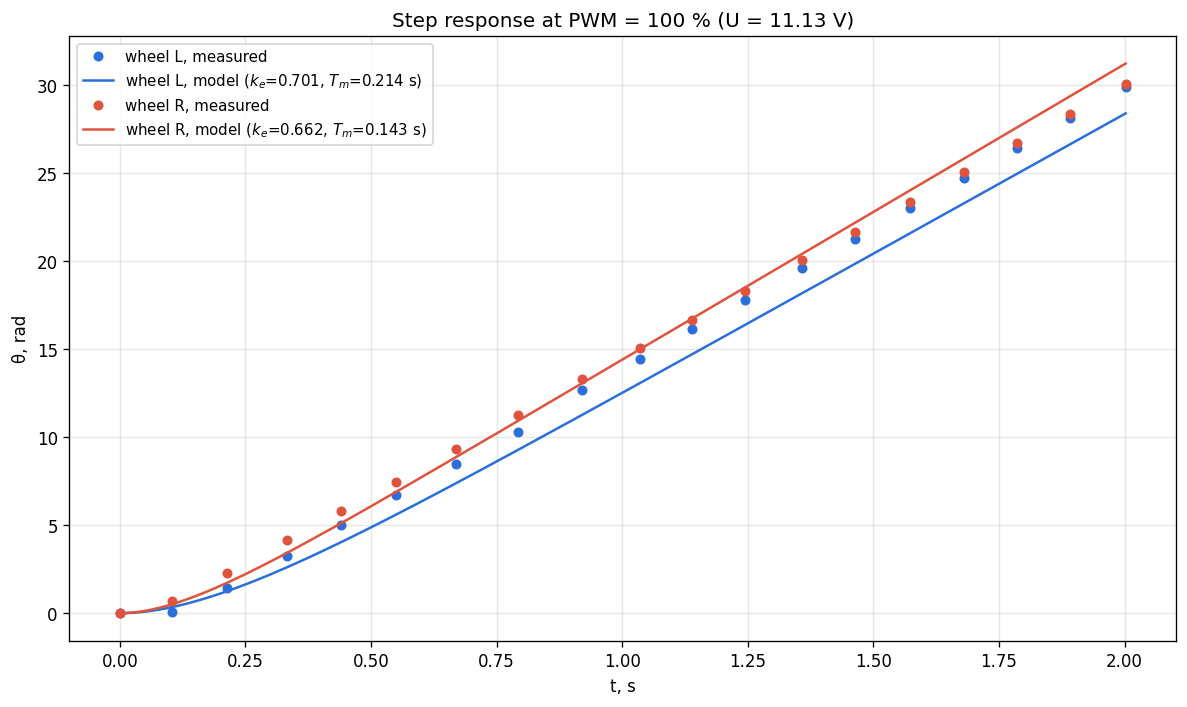

In [5]:
def motor_model(state, t, u, T_m, k_e):
    speed, angle = state                                             # motor state space
    return [-speed / T_m + u / (T_m * k_e), speed]

run = next(r for r in runs if r['power'] == 100)                     # full-power run
t_sim = np.linspace(0, run['time'][-1], 300)                         # fine time grid for the simulation
colors = {'L': '#2a6fdb', 'R': '#e0533d'}

plt.figure(figsize=(10, 6), dpi=120)
for wh in ('L', 'R'):
    s = summary[wh]
    sim = odeint(motor_model, [0, 0], t_sim, args=(run['U'], s['T_m'], s['k_e']))[:, 1]  # simulated angle
    plt.plot(run['time'], run[wh], 'o', color=colors[wh], ms=5, label=f'wheel {wh}, measured')
    plt.plot(t_sim, sim, '-', color=colors[wh], lw=1.5,
             label=f'wheel {wh}, model ($k_e$={s["k_e"]:.3f}, $T_m$={s["T_m"]:.3f} s)')
    err = np.interp(run['time'], t_sim, sim) - run[wh]               # model minus measurement, rad
    print(f'{wh}: max |error| {np.max(np.abs(err)):.2f} rad, error at the end {err[-1]:+.2f} rad '
          f'({100 * err[-1] / run[wh][-1]:+.1f} %)')
plt.xlabel('t, s'); plt.ylabel('θ, rad')
plt.title(f'Step response at PWM = 100 % (U = {run["U"]:.2f} V)')
plt.grid(alpha=0.3); plt.legend(fontsize=9)
plt.tight_layout(); plt.savefig('report_figs/step_response.png')

How much the wheels differ at the same command, and what that does to a differential-drive robot (wheel radius and track width from the Week 4 odometry code). Also: how far the linear model $\omega = U/k_e$ is off at low PWM.

In [6]:
r_wheel, W = 0.0375, 0.194                                           # wheel radius and track width, m
for p in (100, 50, -50, -100):
    i = list(pct).index(p)
    wL, wR = w_ss['L'][i], w_ss['R'][i]
    diff = 100 * (wL - wR) / ((wL + wR) / 2)                         # left vs right, %
    yaw = np.degrees(r_wheel * (wR - wL) / W)                        # deg/s, positive = turning left
    v = r_wheel * (wL + wR) / 2                                      # m/s
    print(f'PWM {p:4d}: wL={wL:6.2f} wR={wR:6.2f} diff={diff:+5.1f} %  yaw rate={yaw:+5.1f} deg/s  v={v:.3f} m/s')

print('linear model error at low PWM (L), %:')
for p in (-30, -20, -10, 10, 20, 30):
    i = list(pct).index(p)
    w_line = U[i] / summary['L']['k_e']                              # what w = U / k_e predicts
    print(f'  PWM {p:4d}: {100 * (w_ss["L"][i] - w_line) / w_ss["L"][i]:.0f} %')

PWM  100: wL= 16.11 wR= 15.55 diff= +3.5 %  yaw rate= -6.1 deg/s  v=0.594 m/s
PWM   50: wL=  9.61 wR= 10.41 diff= -8.0 %  yaw rate= +8.9 deg/s  v=0.375 m/s
PWM  -50: wL= -8.85 wR=-10.63 diff=-18.3 %  yaw rate=-19.7 deg/s  v=-0.365 m/s
PWM -100: wL=-14.59 wR=-15.29 diff= -4.6 %  yaw rate= -7.7 deg/s  v=-0.560 m/s
linear model error at low PWM (L), %:
  PWM  -30: 30 %
  PWM  -20: 44 %
  PWM  -10: 58 %
  PWM   10: 63 %
  PWM   20: 47 %
  PWM   30: 35 %
